# LAB2 - Bài 5 (Trang 26, 27): Heart Disease

Đinh Nhật Huyền Nhân - 6451071055 - CQ.64.CNTT

### Chuẩn bị thư viện

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

### Câu a) Nhập dữ liệu, xóa dòng trống và đổi tên cột

In [2]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# File có ký tự BOM ở đầu nên đọc bằng encoding utf-8-sig
data = pd.read_csv('data/heart.csv', encoding='utf-8-sig')
print('Trước khi xóa dòng trống:', data.shape)
data = data.dropna().reset_index(drop=True)
print('Sau khi xóa dòng trống:', data.shape)

data.columns = ['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol',
                'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved',
                'exercise_induced_angina', 'st_depression', 'st_slope',
                'num_major_vessels', 'thalassemia', 'target']
data.info()

Đinh Nhật Huyền Nhân - 6451071055
Trước khi xóa dòng trống: (303, 14)
Sau khi xóa dòng trống: (303, 14)
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      303 non-null    int64  
 1   sex                      303 non-null    int64  
 2   chest_pain_type          303 non-null    int64  
 3   resting_blood_pressure   303 non-null    int64  
 4   cholesterol              303 non-null    int64  
 5   fasting_blood_sugar      303 non-null    int64  
 6   rest_ecg                 303 non-null    int64  
 7   max_heart_rate_achieved  303 non-null    int64  
 8   exercise_induced_angina  303 non-null    int64  
 9   st_depression            303 non-null    float64
 10  st_slope                 303 non-null    int64  
 11  num_major_vessels        303 non-null    int64  
 12  thalassemia              303 non-null    

### Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson

Đinh Nhật Huyền Nhân - 6451071055


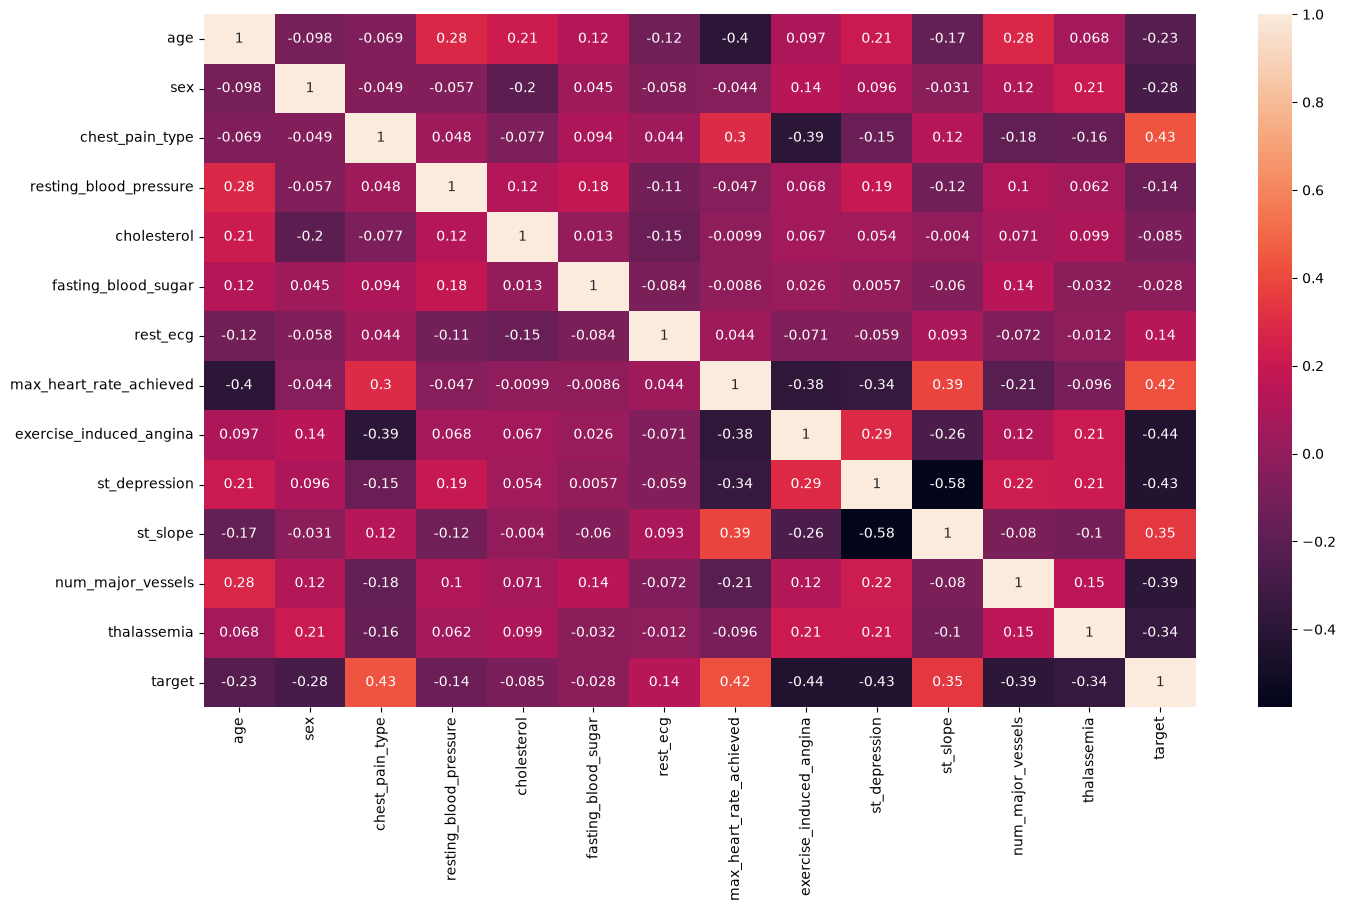

Các cặp có |r| >= 0.8: không có
Cặp tương quan mạnh nhất: st_depression - st_slope = -0.578


In [3]:
print("Đinh Nhật Huyền Nhân - 6451071055")
corr = data.corr(method='pearson', numeric_only=True)
plt.figure(figsize=(16, 9))
sns.heatmap(corr, annot=True)
plt.show()

# Liệt kê các cặp thuộc tính có |r| >= 0.8 (không xét thuộc tính quyết định)
threshold = 0.8
pairs = corr.drop(columns='target', errors='ignore').drop(index='target', errors='ignore')
high_corr = [(a, b, round(pairs.loc[a, b], 3))
             for i, a in enumerate(pairs.columns)
             for b in pairs.columns[i + 1:]
             if abs(pairs.loc[a, b]) >= threshold]
print('Các cặp có |r| >= 0.8:', high_corr if high_corr else 'không có')

# Cặp tương quan mạnh nhất để đối chiếu với ngưỡng
strongest = max(((a, b, pairs.loc[a, b])
                 for i, a in enumerate(pairs.columns)
                 for b in pairs.columns[i + 1:]), key=lambda t: abs(t[2]))
print('Cặp tương quan mạnh nhất:', strongest[0], '-', strongest[1], '=', round(strongest[2], 3))

**Nhận xét:** Không có cặp thuộc tính nào có |r| ≥ 0,8. Cặp tương quan mạnh nhất là st_depression và st_slope với r = -0,578, chưa đến mức cao nên giữ lại toàn bộ các cột.

### Câu 4: Tách thuộc tính bình thường và thuộc tính quyết định

In [4]:
print("Đinh Nhật Huyền Nhân - 6451071055")
features = data.drop('target', axis=1)
labels = data['target']
print('features:', features.shape)
print('labels:', labels.shape)
print(labels.value_counts().sort_index().to_string())

Đinh Nhật Huyền Nhân - 6451071055
features: (303, 13)
labels: (303,)
target
0    138
1    165


### Câu 5: Chuyển các cột không phải dạng số về one-hot vector

In [5]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Chỉ lấy cột không phải dạng số: np.number bao gồm cả int64 và float64
non_numeric = features.select_dtypes(exclude=[np.number]).columns
print('Các cột không phải dạng số:', list(non_numeric))
features_onehot = pd.get_dummies(features, columns=non_numeric, dtype=int)
print('Kích thước sau khi chuyển đổi:', features_onehot.shape)
features_onehot.head()

Đinh Nhật Huyền Nhân - 6451071055
Các cột không phải dạng số: []
Kích thước sau khi chuyển đổi: (303, 13)


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


**Nhận xét:** Tất cả các cột đều là dạng số nên không có cột nào cần chuyển đổi, số cột giữ nguyên là 13. Các cột như chest_pain_type hay thalassemia thực chất là mã phân loại, nhưng đề chỉ yêu cầu chuyển các cột không phải dạng số nên được giữ nguyên.

### Câu 6: Tách dữ liệu huấn luyện và kiểm thử

In [6]:
print("Đinh Nhật Huyền Nhân - 6451071055")
X = features_onehot
y = labels
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print('Number of training data:', len(X_train))
print('Number of test data:', len(X_test))

Đinh Nhật Huyền Nhân - 6451071055
Number of training data: 212
Number of test data: 91


**Nhận xét:** Đề không cho câu lệnh chia dữ liệu ở bài này và dữ liệu chỉ có một file, nên bài dùng cùng cách chia 70/30 với random_state=42 như Bài 4 và Bài 6: 212 mẫu huấn luyện và 91 mẫu kiểm thử.

### Câu 7: Xây dựng cây ID3 và kiểm thử bằng ma trận nhầm lẫn

In [7]:
print("Đinh Nhật Huyền Nhân - 6451071055")
id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
# Train Decision Tree Classifier
id3.fit(X_train, y_train)
print('Độ sâu của cây:', id3.get_depth(), '- Số nút lá:', id3.get_n_leaves())

Đinh Nhật Huyền Nhân - 6451071055
Độ sâu của cây: 7 - Số nút lá: 34


In [8]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Predict the response for test dataset
id3_pred = id3.predict(X_test)

# Model Accuracy, how often is the classifier correct?
id3_score = metrics.accuracy_score(y_test, id3_pred)
print("Accuracy:", id3_score)
print("Report:", metrics.classification_report(y_test, id3_pred, zero_division=0))

Đinh Nhật Huyền Nhân - 6451071055
Accuracy: 0.7252747252747253
Report:               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



Đinh Nhật Huyền Nhân - 6451071055
[[31 10]
 [15 35]]


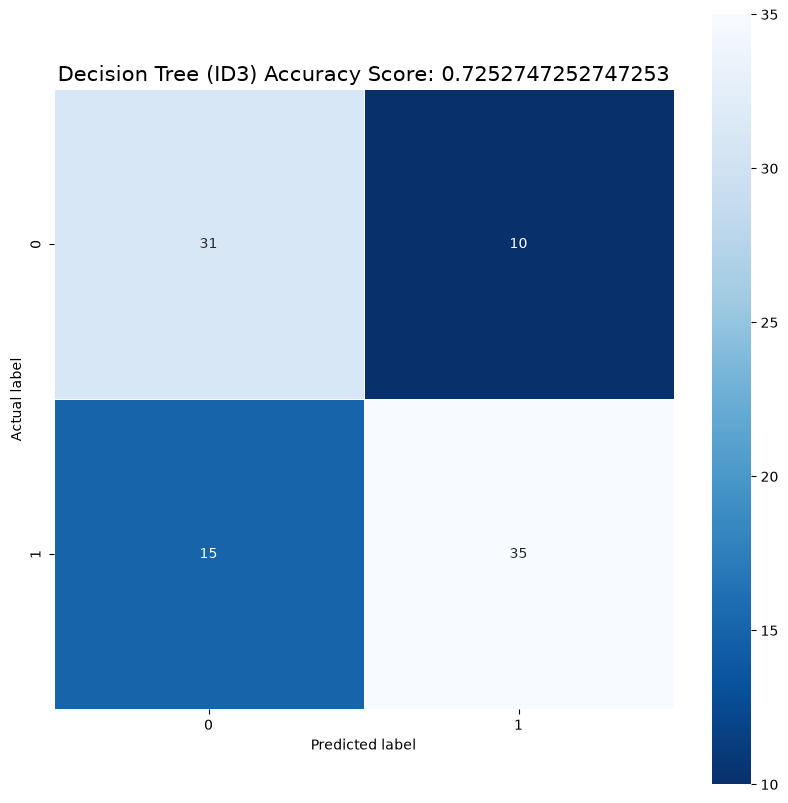

In [9]:
print("Đinh Nhật Huyền Nhân - 6451071055")
id3_cm = metrics.confusion_matrix(y_test, id3_pred, labels=id3.classes_)
print(id3_cm)

plt.figure(figsize=(10, 10))
sns.heatmap(id3_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=id3.classes_, yticklabels=id3.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Decision Tree (ID3) Accuracy Score: {0}'.format(id3_score), size=15)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


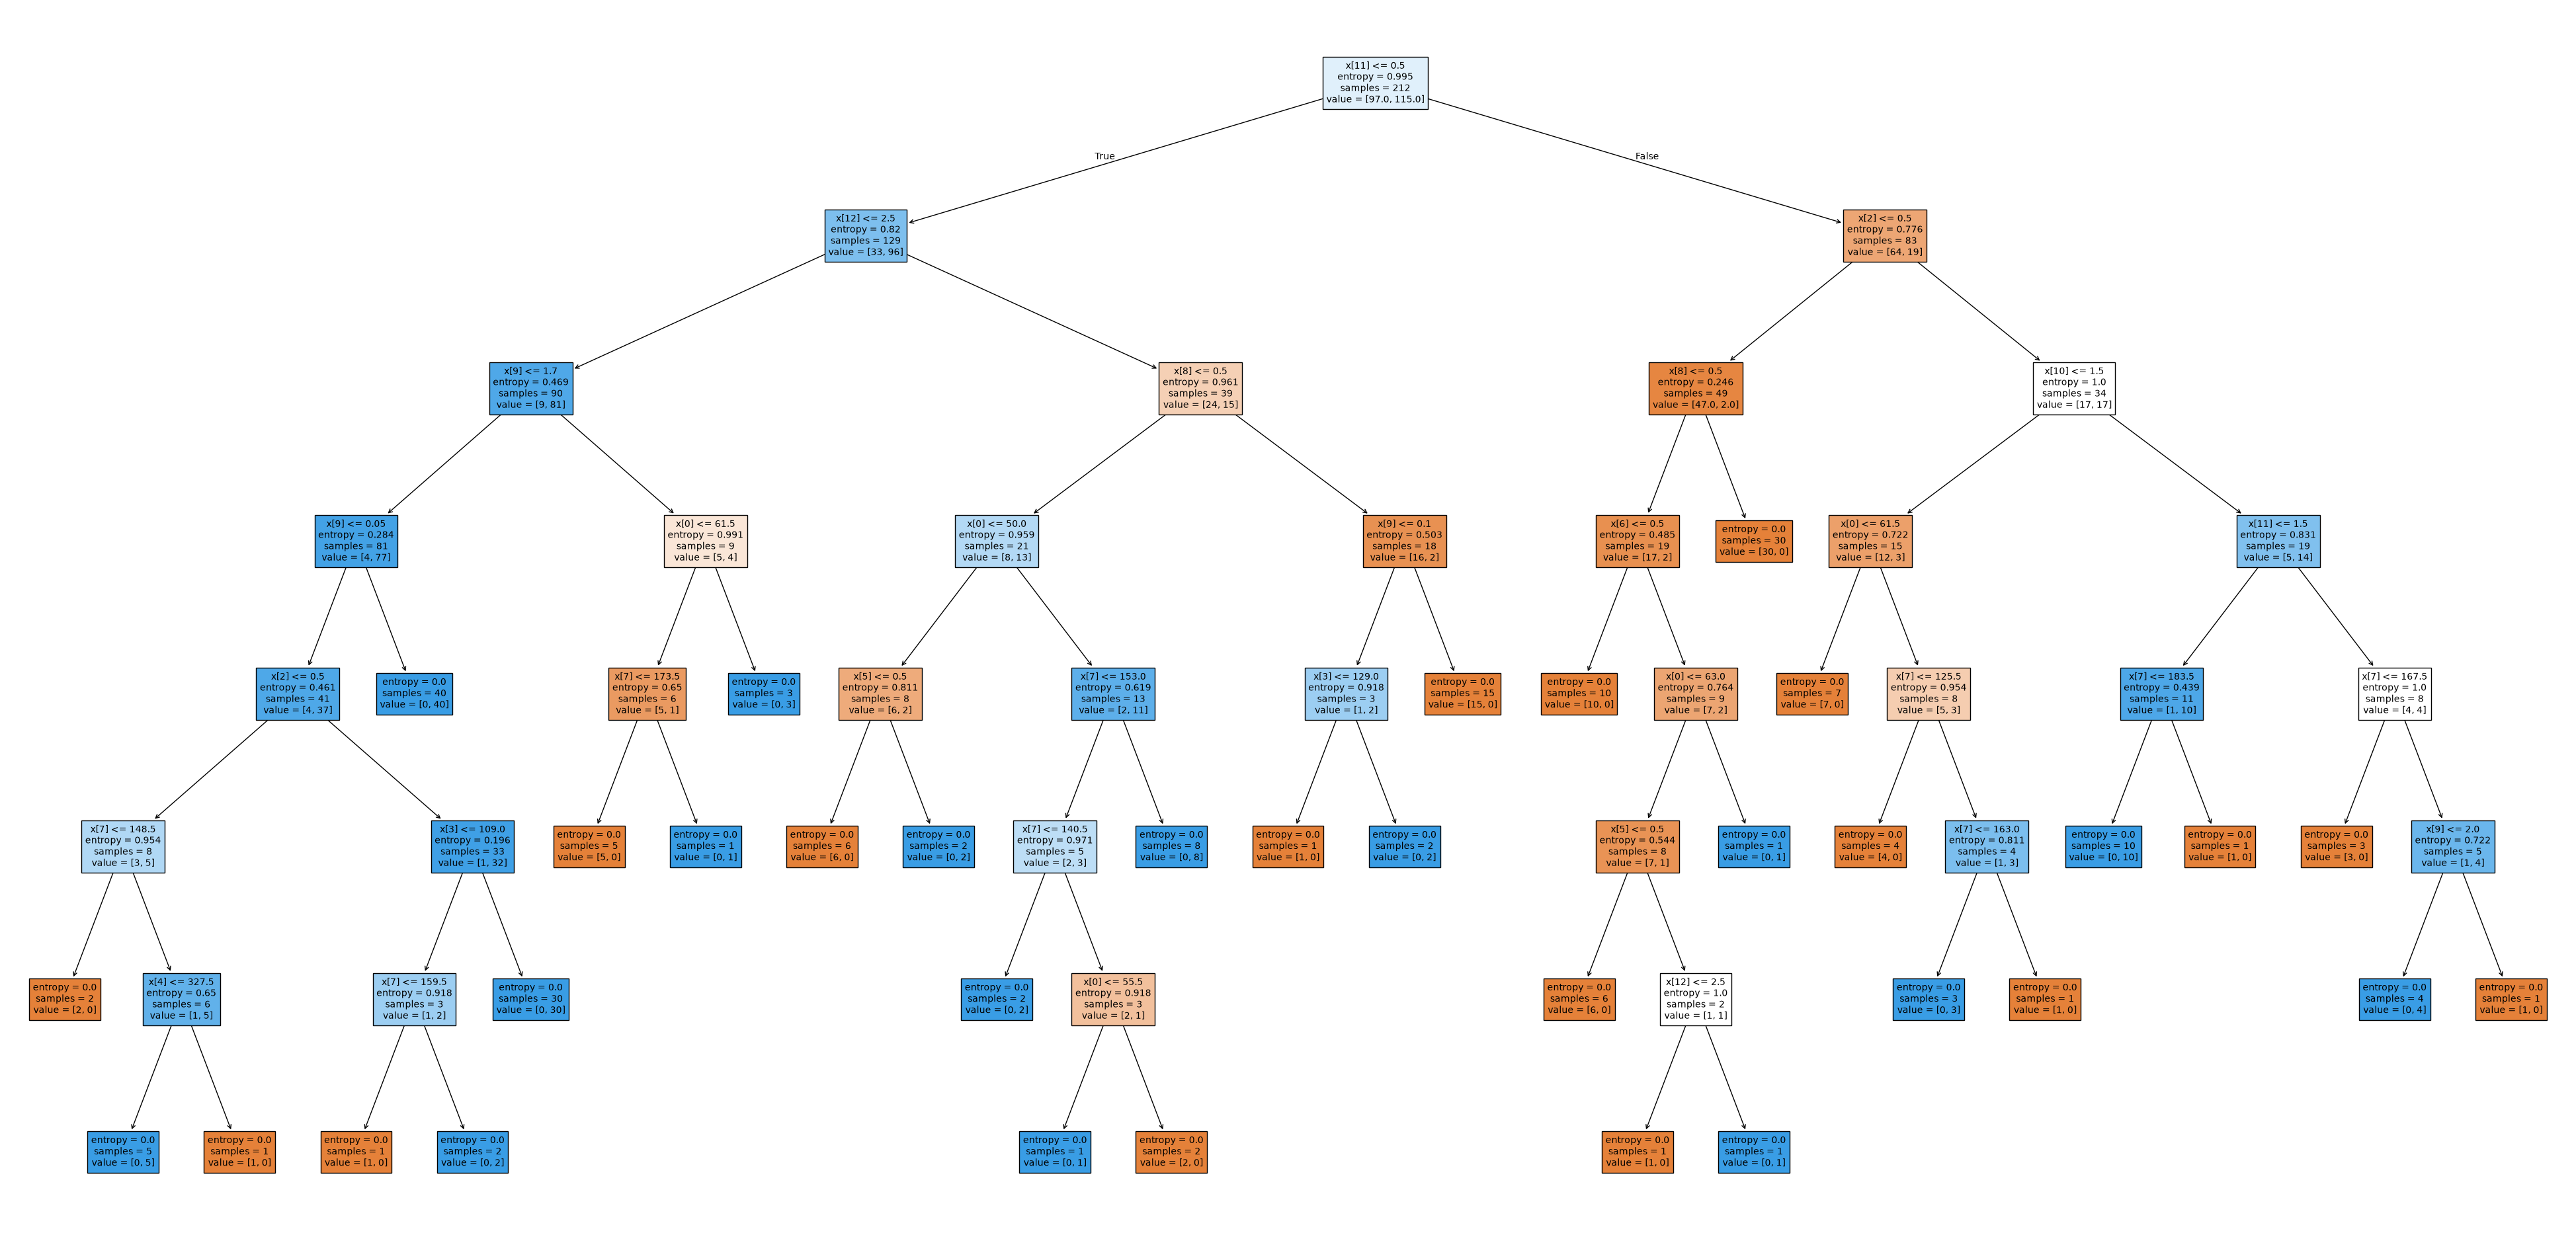

In [10]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Biểu diễn toàn bộ cây và lưu vào file ảnh
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(id3, filled=True, fontsize=10)
plt.savefig('outputs/bai5_id3_tree', dpi=100)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


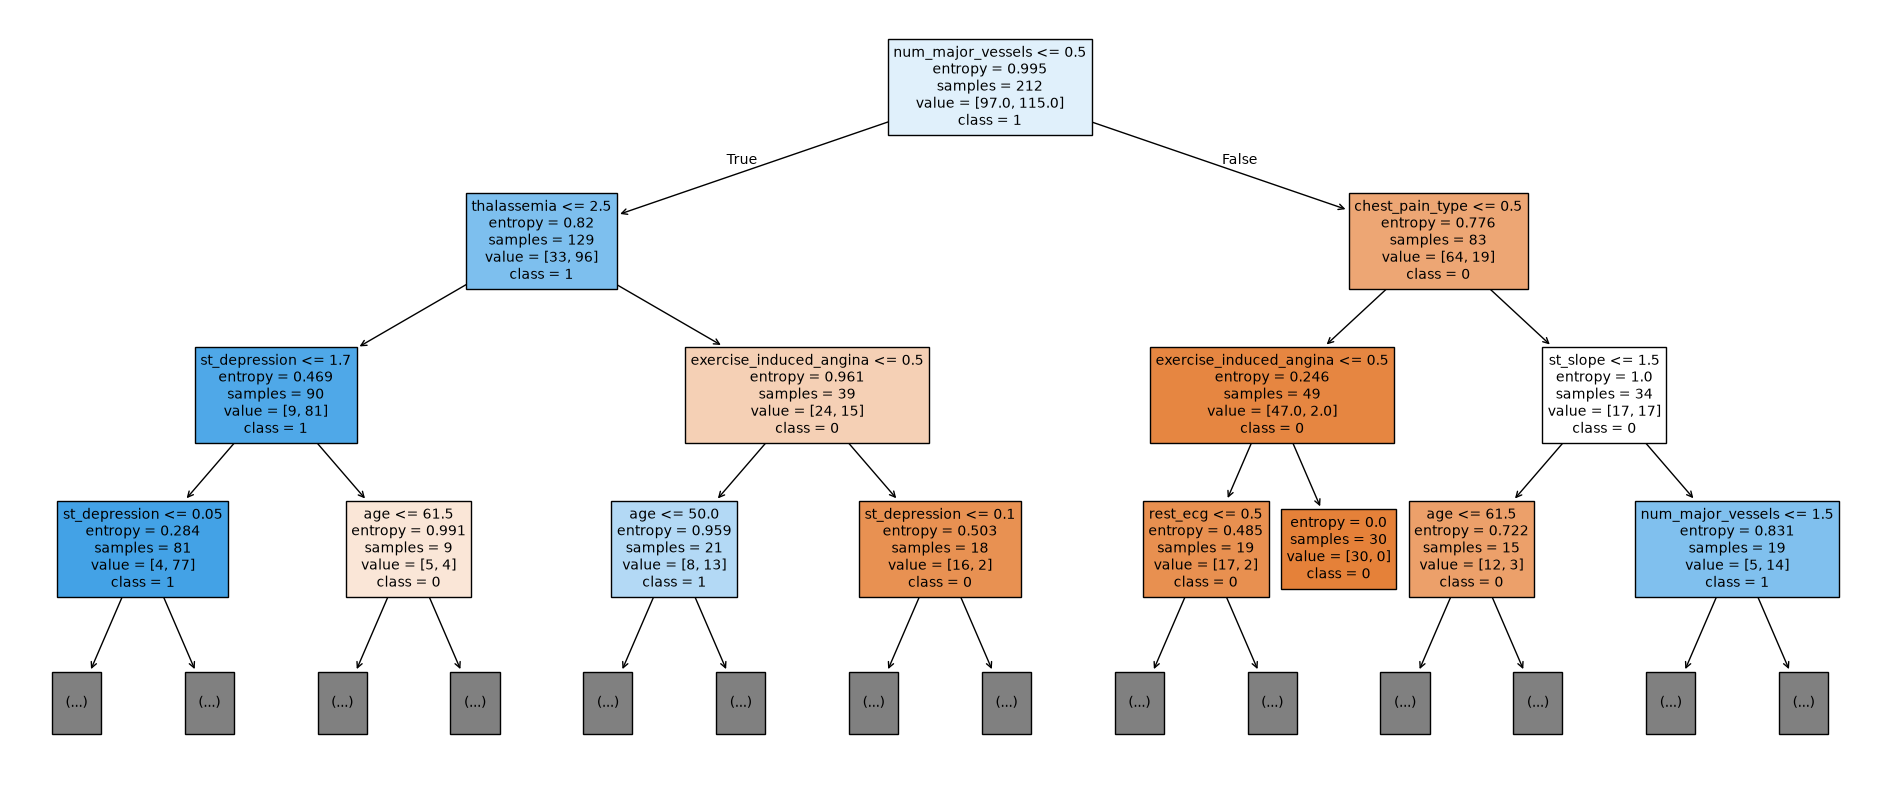

In [11]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Cây đầy đủ rất lớn nên vẽ thêm 3 tầng đầu với tên thuộc tính để dễ đọc
fig, ax = plt.subplots(figsize=(24, 10))
tree.plot_tree(id3, max_depth=3, feature_names=list(X_train.columns),
               class_names=[str(c) for c in id3.classes_], filled=True, fontsize=10)
plt.savefig('outputs/bai5_id3_tree_top3', dpi=100)
plt.show()

### Câu 8: Xây dựng cây CART (criterion='gini')

In [12]:
print("Đinh Nhật Huyền Nhân - 6451071055")
cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
# Train Decision Tree Classifier
cart.fit(X_train, y_train)
print('Độ sâu của cây:', cart.get_depth(), '- Số nút lá:', cart.get_n_leaves())

Đinh Nhật Huyền Nhân - 6451071055
Độ sâu của cây: 9 - Số nút lá: 38


In [13]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Predict the response for test dataset
cart_pred = cart.predict(X_test)

# Model Accuracy, how often is the classifier correct?
cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy:", cart_score)
print("Report:", metrics.classification_report(y_test, cart_pred, zero_division=0))

Đinh Nhật Huyền Nhân - 6451071055
Accuracy: 0.7252747252747253
Report:               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



Đinh Nhật Huyền Nhân - 6451071055
[[31 10]
 [15 35]]


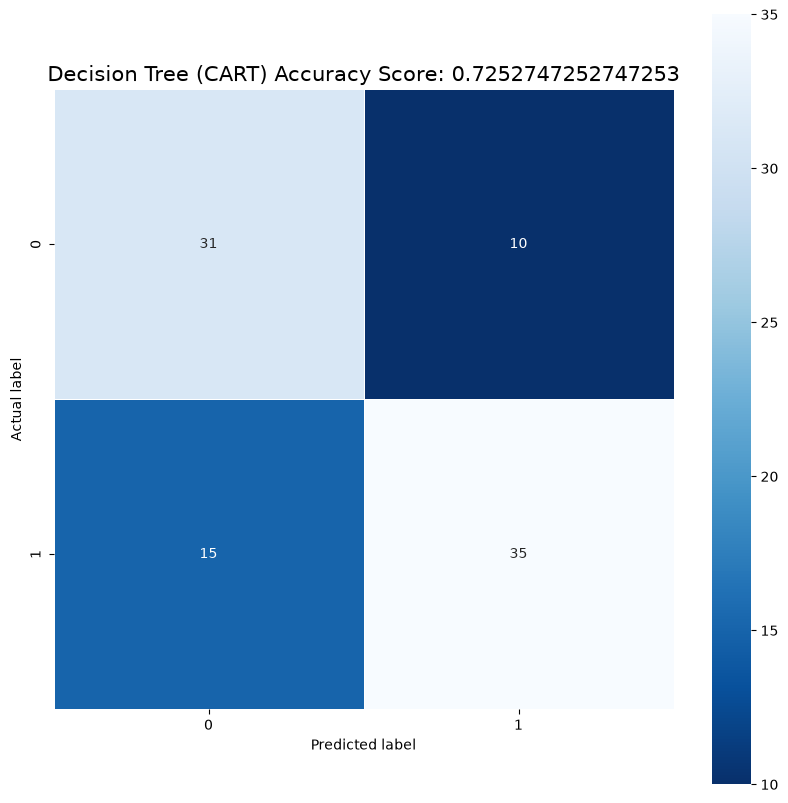

In [14]:
print("Đinh Nhật Huyền Nhân - 6451071055")
cart_cm = metrics.confusion_matrix(y_test, cart_pred, labels=cart.classes_)
print(cart_cm)

plt.figure(figsize=(10, 10))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=cart.classes_, yticklabels=cart.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Decision Tree (CART) Accuracy Score: {0}'.format(cart_score), size=15)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


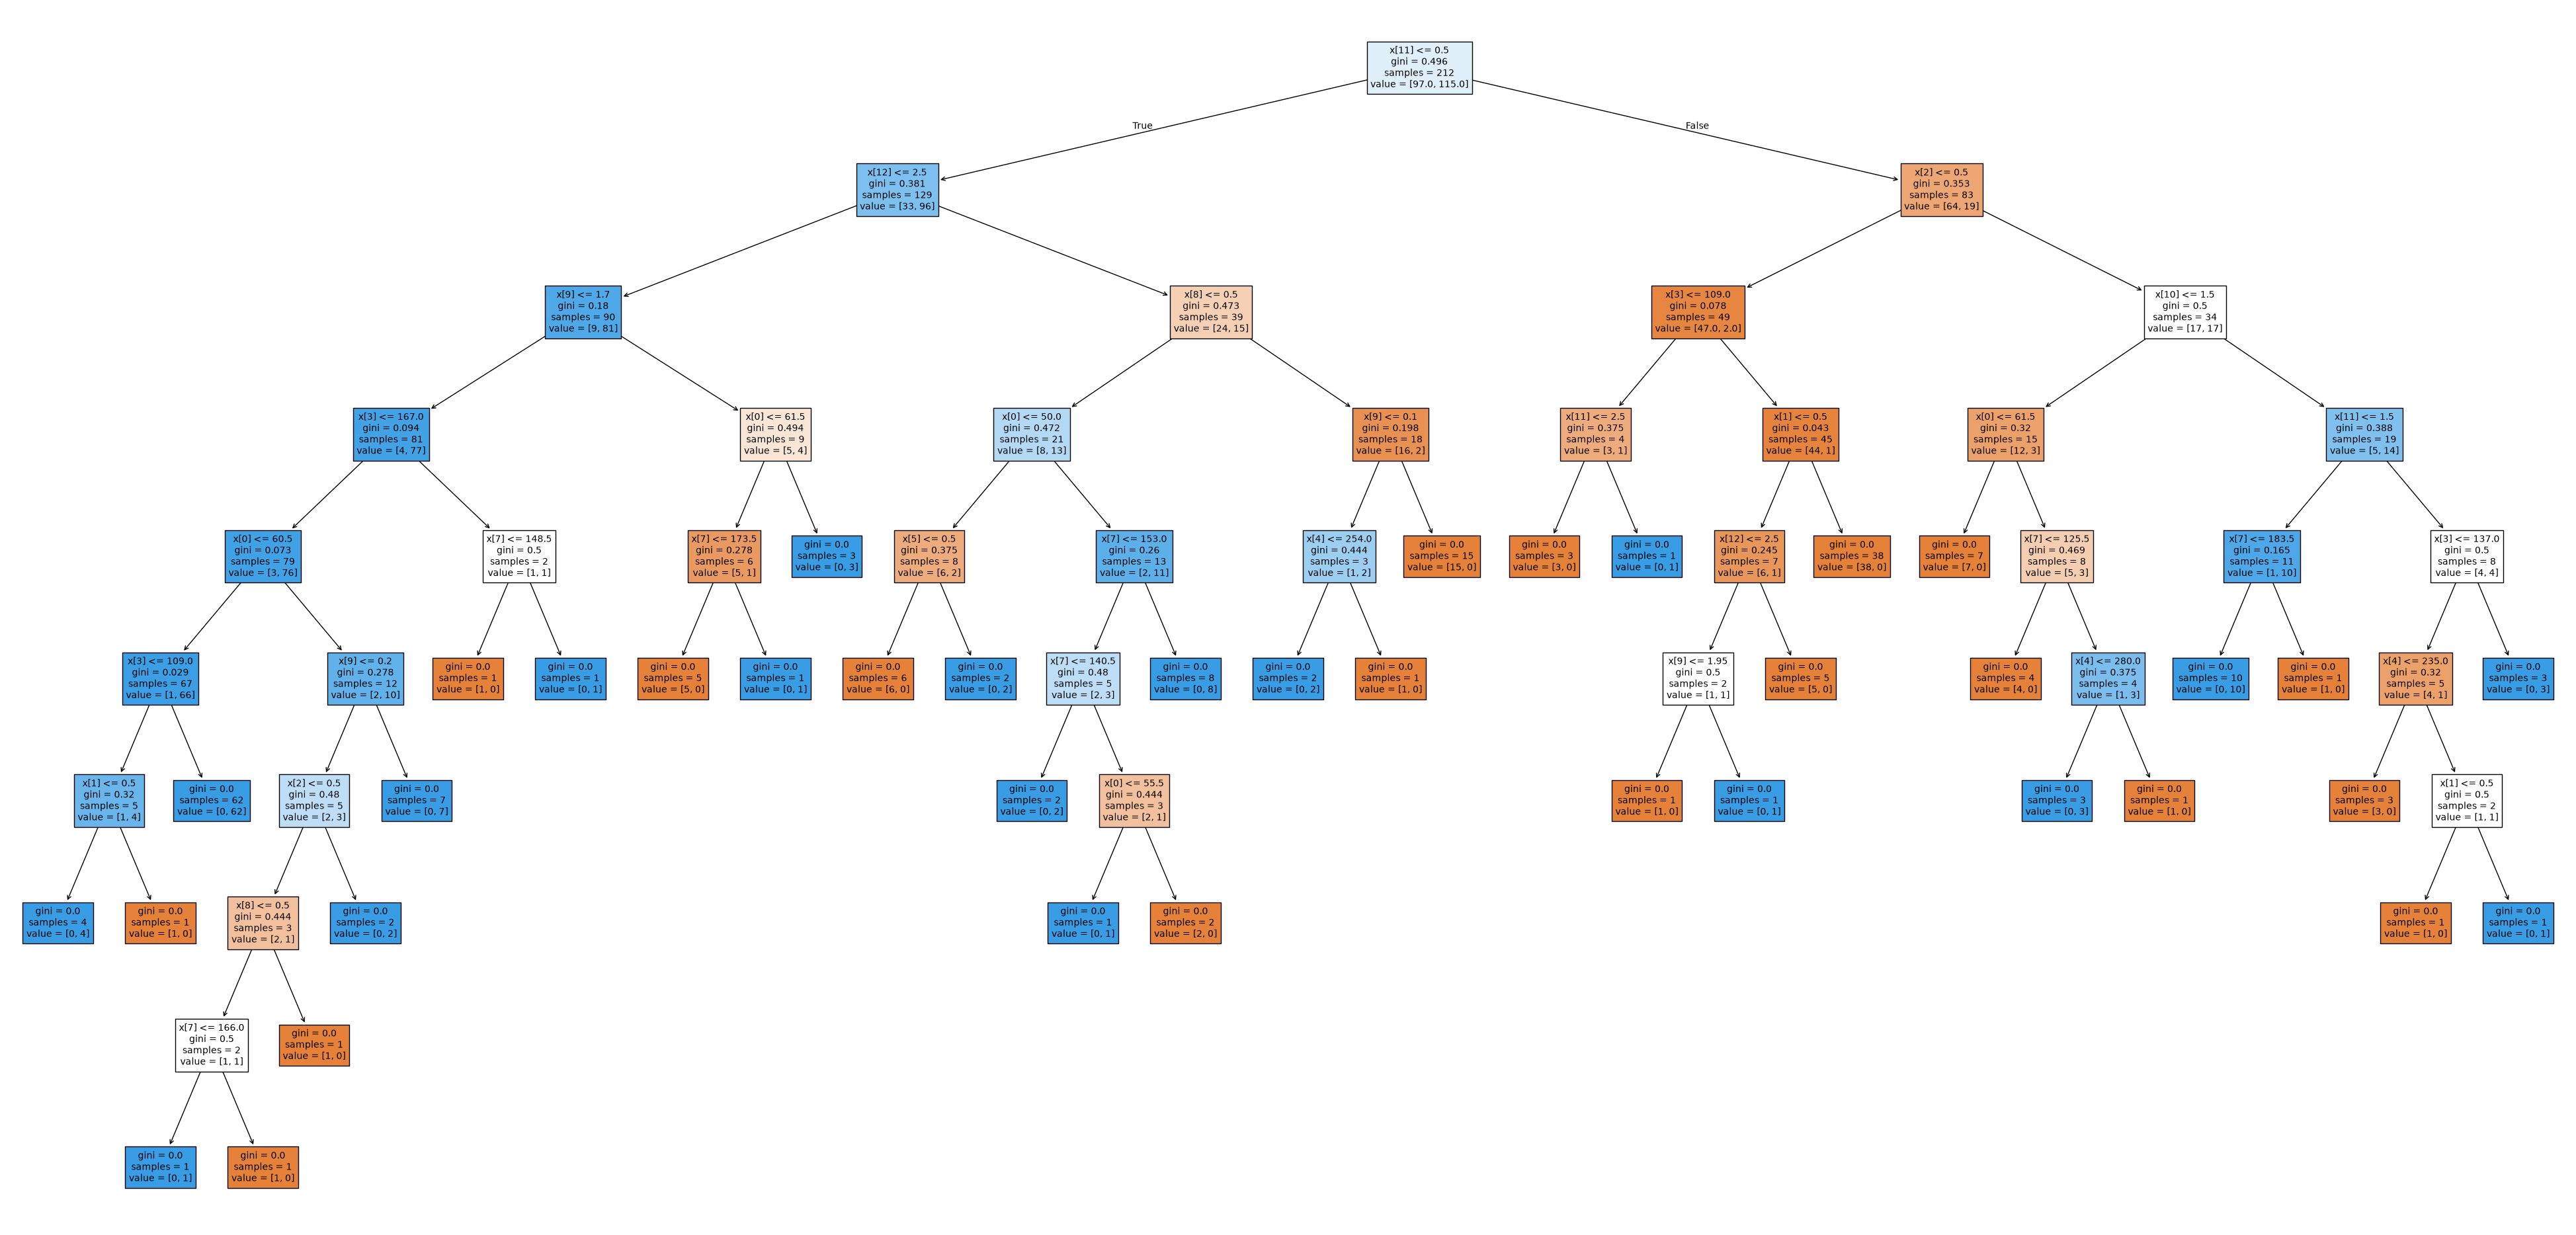

In [15]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Biểu diễn toàn bộ cây và lưu vào file ảnh
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(cart, filled=True, fontsize=10)
plt.savefig('outputs/bai5_cart_tree', dpi=100)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


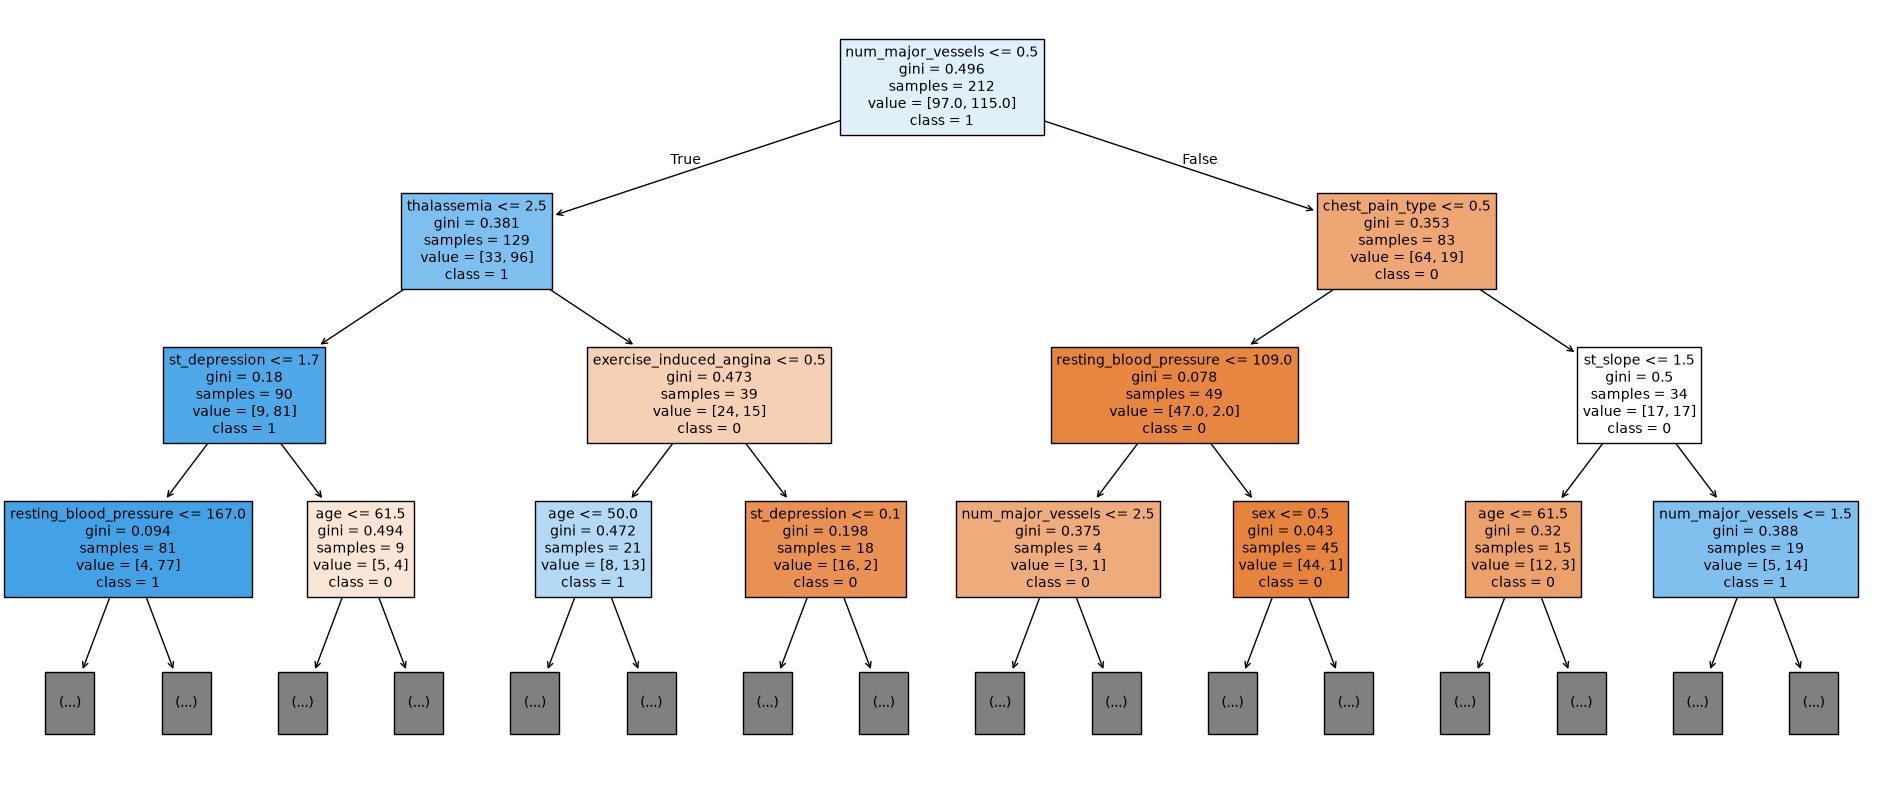

In [16]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Cây đầy đủ rất lớn nên vẽ thêm 3 tầng đầu với tên thuộc tính để dễ đọc
fig, ax = plt.subplots(figsize=(24, 10))
tree.plot_tree(cart, max_depth=3, feature_names=list(X_train.columns),
               class_names=[str(c) for c in cart.classes_], filled=True, fontsize=10)
plt.savefig('outputs/bai5_cart_tree_top3', dpi=100)
plt.show()

### Câu 9: Xây dựng mô hình Naïve Bayes

In [17]:
print("Đinh Nhật Huyền Nhân - 6451071055")
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

Đinh Nhật Huyền Nhân - 6451071055


In [18]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Model Accuracy, how often is the classifier correct?
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:", metrics.classification_report(y_test, bayes_pred, zero_division=0))

Đinh Nhật Huyền Nhân - 6451071055
Accuracy: 0.8351648351648352
Report:               precision    recall  f1-score   support

           0       0.78      0.88      0.83        41
           1       0.89      0.80      0.84        50

    accuracy                           0.84        91
   macro avg       0.84      0.84      0.83        91
weighted avg       0.84      0.84      0.84        91



Đinh Nhật Huyền Nhân - 6451071055
[[36  5]
 [10 40]]


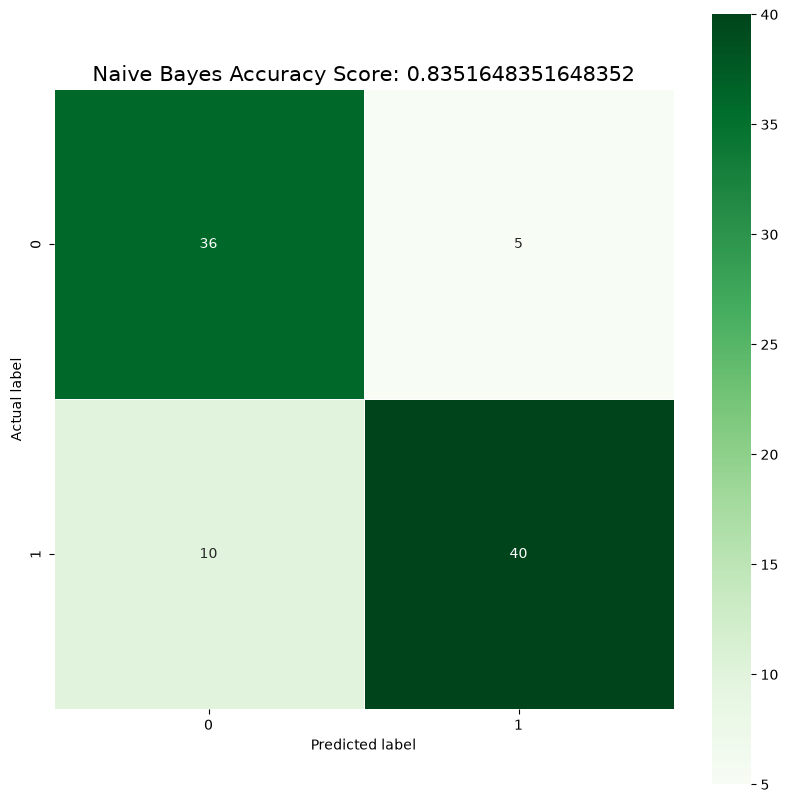

In [19]:
print("Đinh Nhật Huyền Nhân - 6451071055")
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred, labels=gnb.classes_)
print(bayes_cm)

plt.figure(figsize=(10, 10))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Naive Bayes Accuracy Score: {0}'.format(bayes_score), size=15)
plt.show()

### Câu 10: So sánh kết quả của các mô hình

In [20]:
print("Đinh Nhật Huyền Nhân - 6451071055")
models = {'ID3': (id3, id3_pred), 'CART': (cart, cart_pred), 'Naive Bayes': (gnb, bayes_pred)}
rows = []
for name, (model, pred) in models.items():
    report = metrics.classification_report(y_test, pred, output_dict=True, zero_division=0)
    rows.append({'Model': name,
                 'Train acc': model.score(X_train, y_train),
                 'Test acc': report['accuracy'],
                 'Macro P': report['macro avg']['precision'],
                 'Macro R': report['macro avg']['recall'],
                 'Macro F1': report['macro avg']['f1-score'],
                 'Weighted F1': report['weighted avg']['f1-score']})
print(pd.DataFrame(rows).set_index('Model').round(4).to_string())

classes = sorted(y_test.unique())
print('\nĐộ chính xác (precision) theo từng lớp:')
print(pd.DataFrame({name: metrics.precision_score(y_test, pred, labels=classes, average=None, zero_division=0)
                    for name, (_, pred) in models.items()}, index=classes).round(4).to_string())
print('\nĐộ phủ (recall) theo từng lớp:')
print(pd.DataFrame({name: metrics.recall_score(y_test, pred, labels=classes, average=None, zero_division=0)
                    for name, (_, pred) in models.items()}, index=classes).round(4).to_string())

Đinh Nhật Huyền Nhân - 6451071055
             Train acc  Test acc  Macro P  Macro R  Macro F1  Weighted F1
Model                                                                    
ID3             1.0000    0.7253   0.7258    0.728    0.7247       0.7259
CART            1.0000    0.7253   0.7258    0.728    0.7247       0.7259
Naive Bayes     0.8302    0.8352   0.8357    0.839    0.8348       0.8356

Độ chính xác (precision) theo từng lớp:
      ID3    CART  Naive Bayes
0  0.6739  0.6739       0.7826
1  0.7778  0.7778       0.8889

Độ phủ (recall) theo từng lớp:
      ID3    CART  Naive Bayes
0  0.7561  0.7561        0.878
1  0.7000  0.7000        0.800


**Nhận xét:** Naïve Bayes tốt nhất trên cả accuracy (0,8352) và Macro F1 (0,8348). ID3 và CART có cùng accuracy (0,7253) và cùng ma trận nhầm lẫn dù cấu trúc cây khác nhau (sâu 7 và 9 tầng). Với lớp có bệnh, Naïve Bayes bỏ sót 10/50 bệnh nhân, còn hai cây bỏ sót 15/50. Trong chẩn đoán, bỏ sót bệnh nhân là lỗi nghiêm trọng nên Naïve Bayes phù hợp hơn. Hai cây đạt accuracy 1,0 trên tập huấn luyện nên bị quá khớp, còn Naïve Bayes ổn định (0,8302 và 0,8352). Tập kiểm thử chỉ có 91 mẫu nên kết quả có thể thay đổi khi chia dữ liệu theo cách khác.